# 1. Single Non-Dispersive Interface: Analytical Fresnel Equations & EMUstack S-Matrix

## Physical Motivation & Learning Objectives
When plane waves encounter a planar interface separating two optical media of refractive indices $n_1$ and $n_2$, light undergoes reflection and transmission governed by **Fresnel's equations**. In EMUstack, homogeneous layers are modeled via the analytic `ThinFilm` class, which expands fields into a spatial Fourier series of plane-wave diffraction orders.

In this tutorial, you will learn:
1. How to define non-dispersive planar layers (`objects.ThinFilm`) and incident illumination (`objects.Light`).
2. Why an artificial unit-cell period ($\Lambda$) is assigned to homogeneous layers, and how `max_order_PWs` governs diffraction orders.
3. How to verify numerical reflection against analytical Fresnel formulas.
4. How to inspect propagation constants ($k_z$) and scattering matrices ($R_{\mathrm{net}}$).


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## Illumination & Layer Definitions

We simulate a normal-incidence beam ($	heta = 0^\circ, \phi = 0^\circ$) across $\lambda \in [500, 600]$ nm. The superstrate has refractive index $n_1 = 1.5$ and the substrate has $n_2 = 3.0$.

For homogeneous planar films, an artificial period $\Lambda = 300$ nm is chosen. All layers in a simulation stack must share the same period.


In [2]:
wavelengths = np.linspace(500, 600, 5)
period = 300.0  # nm

light_list = [
    objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0, n_inc=1.5)
    for wl in wavelengths
]

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Material(1.5 + 0.0j))
substrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Material(3.0 + 0.0j))


## Stack Scattering Matrix Evaluation

We calculate the eigenmodes of each layer and assemble the 2-layer `Stack`. Because the media are non-dispersive, the reflectance is wavelength-independent.


In [3]:
def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    stk = Stack((sim_sub, sim_sup))
    stk.calc_scat(pol='TE')
    return stk

stacks_list = [simulate_stack(light) for light in light_list]
print(f"Evaluated {len(stacks_list)} wavelengths successfully.")


Evaluated 5 wavelengths successfully.


## Analytical Verification Against Fresnel Reflection

At normal incidence, the Fresnel reflection coefficient is:
$$r = \frac{n_1 - n_2}{n_1 + n_2} = \frac{1.5 - 3.0}{1.5 + 3.0} = \frac{-1.5}{4.5} = -\frac{1}{3}$$
$$R_{\mathrm{analytical}} = |r|^2 = \frac{1}{9} \approx 0.111111$$


In [4]:
n1, n2 = 1.5, 3.0
R_analytical = ((n1 - n2) / (n1 + n2))**2
R_emustack = float(stacks_list[0].r_list[-1])

print(f"Analytical Fresnel Reflectance: {R_analytical:.6f}")
print(f"EMUstack S-Matrix Reflectance:   {R_emustack:.6f}")
print(f"Absolute Difference:             {abs(R_analytical - R_emustack):.2e}")
assert abs(R_analytical - R_emustack) < 1e-10, "EMUstack does not match analytical Fresnel formula!"


Analytical Fresnel Reflectance: 0.111111
EMUstack S-Matrix Reflectance:   0.111111
Absolute Difference:             3.44e-15


## Scattering Matrix Visualization & Reflection Spectra

Because both layers are homogeneous, the reflection scattering matrix $R_{\mathrm{net}}$ is strictly diagonal (no coupling between diffraction orders).


<ipython-input-1-e3128440121d>:3: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
<ipython-input-1-e3128440121d>:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


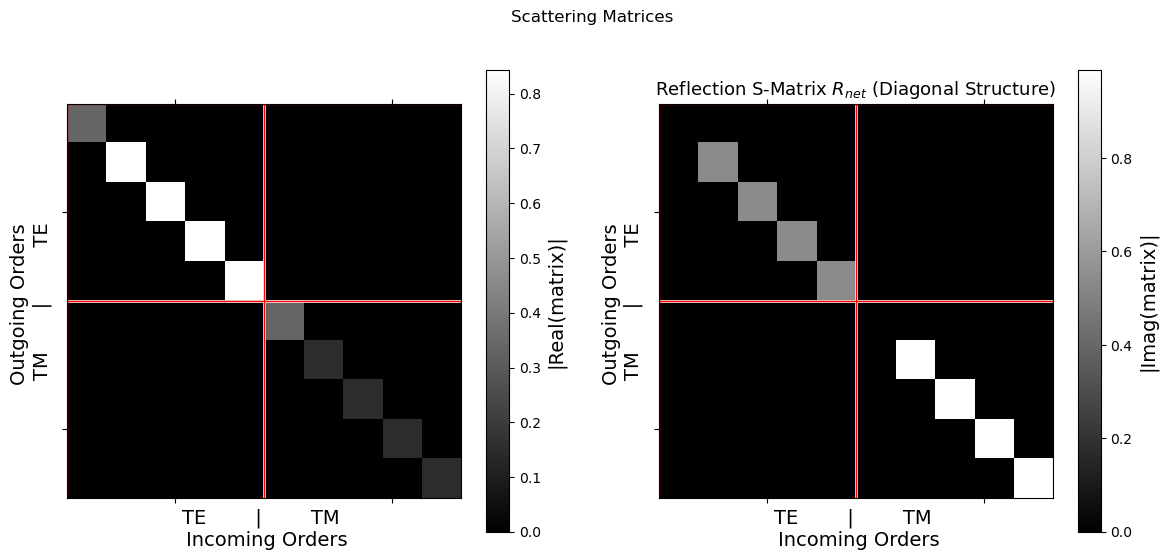

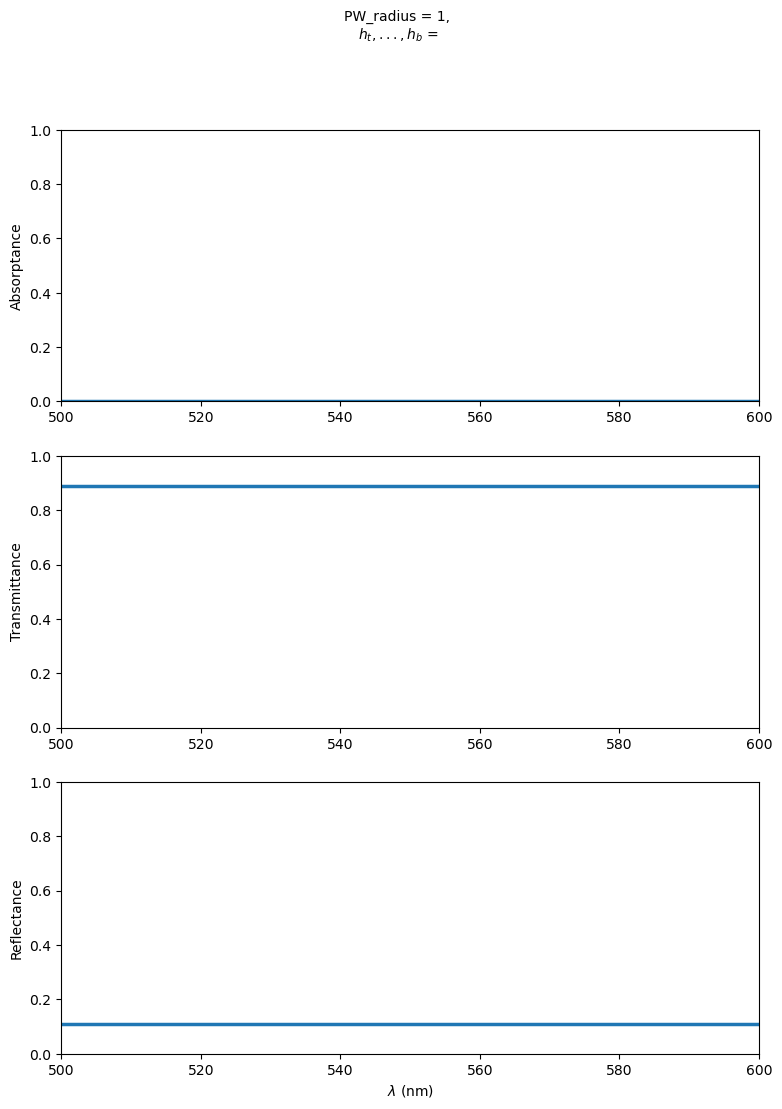

In [5]:
fig_mat = plotting.vis_scat_mats(stacks_list[0].R_net, save_pdf=False)
plt.title("Reflection S-Matrix $R_{net}$ (Diagonal Structure)", fontsize=13)
plt.show()

fig_tra = plotting.t_r_a_plots(stacks_list, save_pdf=False, save_txt=False)
plt.show()


## Physical Interpretation
- The reflectance is flat across the spectrum at exactly $R = 1/9 \approx 11.11\%$ and transmission is $T = 1 - R = 88.89\%$.
- No absorption occurs because both materials have zero imaginary refractive index.
- The off-diagonal blocks of the scattering matrix remain zero to machine precision, confirming that homogeneous planar interfaces conserve transverse momentum.
